# Example: Modelling time-varying amplitude and functional connectivity in fMRI recordings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
from glhmm import glhmm, preproc, utils, graphics

In [2]:
data = pd.read_csv('./GLHMM/data.csv', header=None).to_numpy()
T_t = pd.read_csv('./GLHMM/T.csv', header=None).to_numpy()

In [ ]:
data.shape # (number of timepoints, number of features)

(20000, 50)

In [ ]:
T_t.shape #(20 = number of subjects, 2nd dimension represents the start and end timepoints of each subject's data)

(20, 2)

In [12]:
T_t

array([[    0,  1000],
       [ 1000,  2000],
       [ 2000,  3000],
       [ 3000,  4000],
       [ 4000,  5000],
       [ 5000,  6000],
       [ 6000,  7000],
       [ 7000,  8000],
       [ 8000,  9000],
       [ 9000, 10000],
       [10000, 11000],
       [11000, 12000],
       [12000, 13000],
       [13000, 14000],
       [14000, 15000],
       [15000, 16000],
       [16000, 17000],
       [17000, 18000],
       [18000, 19000],
       [19000, 20000]], dtype=int64)

Standardising will be done separately for each session/subject as specified in the indices. The data provided here are already close to standardised (so the code below will not do much).

In [3]:
data,_,log = preproc.preprocess_data(data, T_t)

**Initialise and train an HMM**

HMM, since we do not want to model an interaction between two sets of variables, we set model_beta='no'. The number of states is specified using the K parameter. We here estimate K=4 states.

In [5]:
hmm = glhmm.glhmm(model_beta='no', K=4, covtype='full', preproclogY=log)
print(hmm.hyperparameters)

{'K': 4, 'covtype': 'full', 'model_mean': 'state', 'model_beta': 'no', 'dirichlet_diag': 10, 'connectivity': None, 'Pstructure': array([[ True,  True,  True,  True],
       [ True,  True,  True,  True],
       [ True,  True,  True,  True],
       [ True,  True,  True,  True]]), 'Pistructure': array([ True,  True,  True,  True])}


We then train the HMM using the data and indices loaded above. Since we here do not model an interaction between two sets of timeseries but run a standard HMM instead, we set X=None. Y should be the timeseries in which we want to estimate states (in here called data) and indices should be the beginning and end indices of each subject (here called T_t)

Optionally, you can also return Gamma (the state probabilities at each timepoint), Xi (the joint probabilities of past and future states conditioned on the data) and FE (the free energy of each iteration) at this step, but it is also possible to retrieve them later using the decode function for Gamma and Xi and the get_fe function for the free energy.

In [6]:
np.random.seed(123)
Gamma,Xi,FE = hmm.train(X=None, Y=data, indices=T_t)

Init repetition 1 free energy = 1379115.6890969852
Init repetition 2 free energy = 1378891.257034655
Init repetition 3 free energy = 1379798.21304692
Init repetition 4 free energy = 1381062.6984172328
Init repetition 5 free energy = 1380353.8282306655
Best repetition: 2
Cycle 1 free energy = 1378772.8034008371
Cycle 2 free energy = 1378254.5995847979
Cycle 3, free energy = 1377970.292081379, relative change = 0.3542722657304983
Cycle 4, free energy = 1377718.011712676, relative change = 0.23917553725037383
Cycle 5, free energy = 1377518.1552216054, relative change = 0.15929285546236707
Cycle 6, free energy = 1377330.6164512094, relative change = 0.13003776690979055
Cycle 7, free energy = 1377164.89763957, relative change = 0.10306500270809552
Cycle 8, free energy = 1377033.5499644922, relative change = 0.07551957198019453
Cycle 9, free energy = 1376922.296076953, relative change = 0.06012074964704515
Cycle 10, free energy = 1376824.857938874, relative change = 0.05002097850352724
Cycle

# Inspect model

**State means: Time-varying amplitude patterns**

In [9]:
K = hmm.hyperparameters["K"] # the number of states
q = data.shape[1] # the number of parcels/channels
state_means = np.zeros(shape=(q, K))
state_means = hmm.get_means() # the state means in the shape (no. features, no. states)

We can then plot these amplitude patterns. This will show the states on the x-axis, each parcel/brain region/channel on the y-axis, and the mean activation of each parcel in each state as the color intensity.

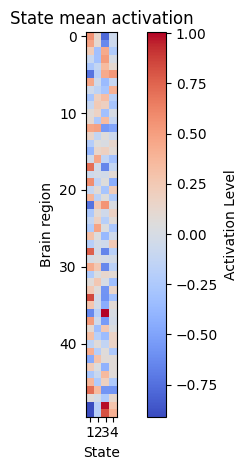

In [13]:
cmap = "coolwarm"
plt.imshow(state_means, cmap=cmap,interpolation="none")
plt.colorbar(label='Activation Level') # Label for color bar
plt.title("State mean activation")
plt.xticks(np.arange(K), np.arange(1,K+1))
plt.gca().set_xlabel('State')
plt.gca().set_ylabel('Brain region')
plt.tight_layout()  # Adjust layout for better spacing
plt.show()

**State covariances: Time-varying functional connectivity**

The state covariances represent the time-varying functional connectivity patterns that we have estimated in the fMRI recordings. They can be obtained from the model using the get_covariance_matrix function:

In [14]:
state_FC = np.zeros(shape=(q, q, K))
for k in range(K):
    state_FC[:,:,k] = hmm.get_covariance_matrix(k=k) # the state covariance matrices in the shape (no. features, no. features, no. states)

We can then plot the covariance (i.e., functional connectivity) of each state. 
These are square matrices showing the brain region by brain region functional connectivity patterns:


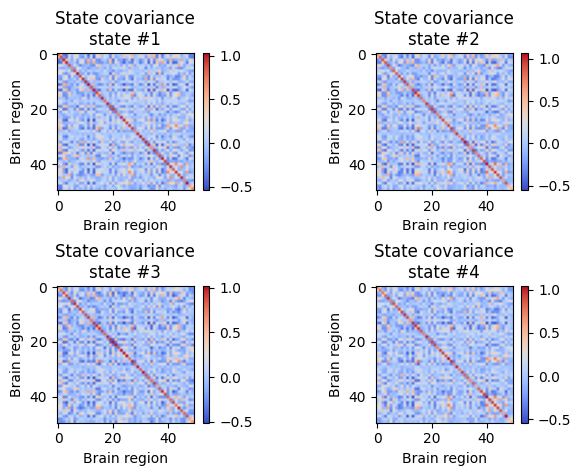

In [ ]:
for k in range(K):
    plt.subplot(2,2,k+1)
    plt.imshow(state_FC[:,:,k],cmap=cmap)
    plt.xlabel('Brain region')
    plt.ylabel('Brain region')
    plt.colorbar()
    plt.title("State covariance\nstate #%s" % (k+1))
plt.subplots_adjust(hspace=0.7, wspace=0.8)
plt.show()

**Transition probabilities**

The transition probabilities indicate the temporal order in the state sequence, i.e., the probability of transitioning from any one state to any other state. They are contained in hmm.P with a shape of [K, K]:

In [16]:
TP = hmm.P.copy() # The transition probability matrix

We can then plot the transition probability matrix. Note that self-transitions (i.e., staying in the same state) are considerably more likely in a timeseries that has some order, so there should be a strong diagonal pattern. For comparison, we also show the transition probabilities excluding self-transitions:

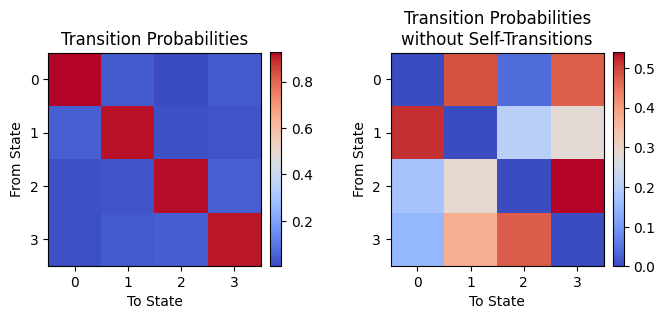

In [17]:
# Plot Transition Probabilities
plt.figure(figsize=(7, 4))

# Plot 1: Original Transition Probabilities
plt.subplot(1, 2, 1)
plt.imshow(TP, cmap=cmap, interpolation='nearest')  # Improved color mapping
plt.title('Transition Probabilities')
plt.xlabel('To State')
plt.ylabel('From State')
plt.colorbar(fraction=0.046, pad=0.04)

# Plot 2: Transition Probabilities without Self-Transitions
TP_noself = TP - np.diag(np.diag(TP))  # Remove self-transitions
TP_noself2 = TP_noself / TP_noself.sum(axis=1, keepdims=True)  # Normalize probabilities
plt.subplot(1, 2, 2)
plt.imshow(TP_noself2, cmap=cmap, interpolation='nearest')  # Improved color mapping
plt.title('Transition Probabilities\nwithout Self-Transitions')
plt.xlabel('To State')
plt.ylabel('From State')
plt.colorbar(fraction=0.046, pad=0.04)

plt.tight_layout()  # Adjust layout for better spacing
plt.show()

**Viterbi path**


The Viterbi path is a discrete representation of the state timecourse, indicating which state is active at which timepoint. 

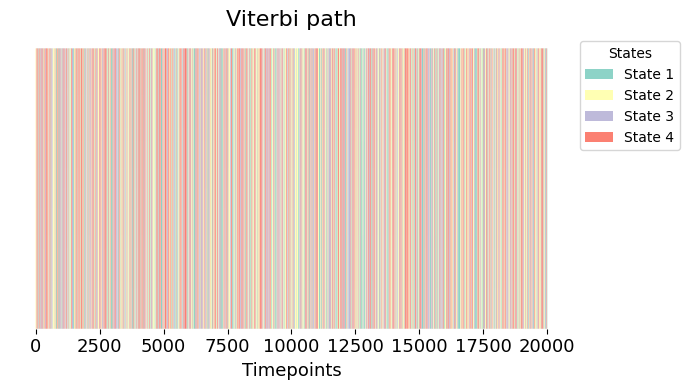

In [18]:
vpath = hmm.decode(X=None, Y=data, indices=T_t, viterbi=True)
graphics.plot_vpath(vpath, title="Viterbi path")

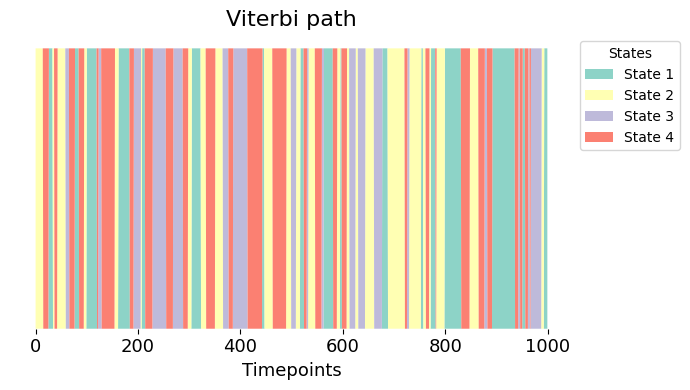

In [19]:
num_subject = 0
graphics.plot_vpath(vpath[T_t[num_subject,0]:T_t[num_subject,1],:], title="Viterbi path")

**Summary metrics**

The fractional occupancy (FO) indicates the fraction of time in each session that is occupied by each state. For instance, if one state was active for the entire duration of the session, this state’s FO would be 1 (100%) and all others would be 0. If, on the other hand, all states are present for an equal amount of timepoints in total, the FO of all states would be 1/K (the number of states). 

 This can be informative to understand whether one state is more present in a certain group of subjects or experimental condition, or to interrogate mixing (explained above).

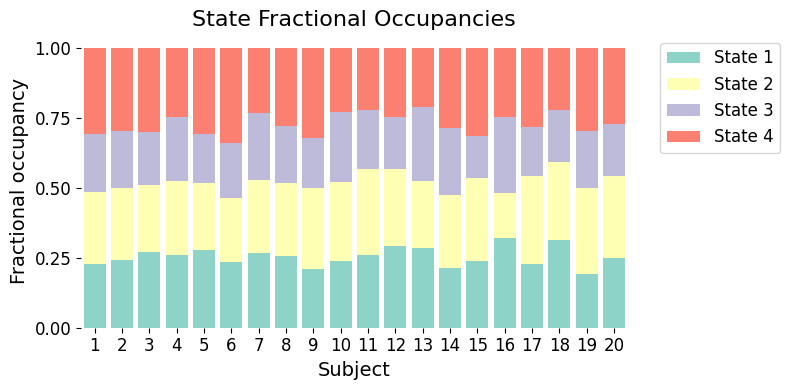

In [20]:
FO = utils.get_FO(Gamma, indices=T_t)
graphics.plot_FO(FO, num_x_ticks=FO.shape[0])

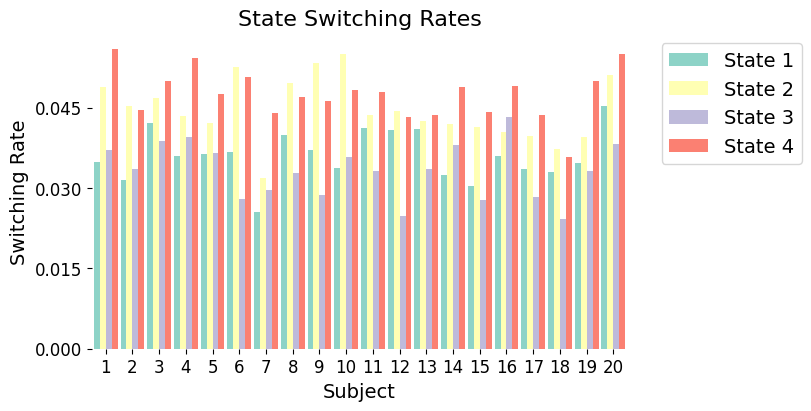

In [21]:
SR = utils.get_switching_rate(Gamma, T_t)
graphics.plot_switching_rates(SR, num_x_ticks=SR.shape[0])

The state lifetimes (also called dwell times) indicate how long a state is active at a time (either on average, median, or maximum). This can be informative to understand whether states tend to last longer or shorter times, pointing towards slower vs. faster dynamics:

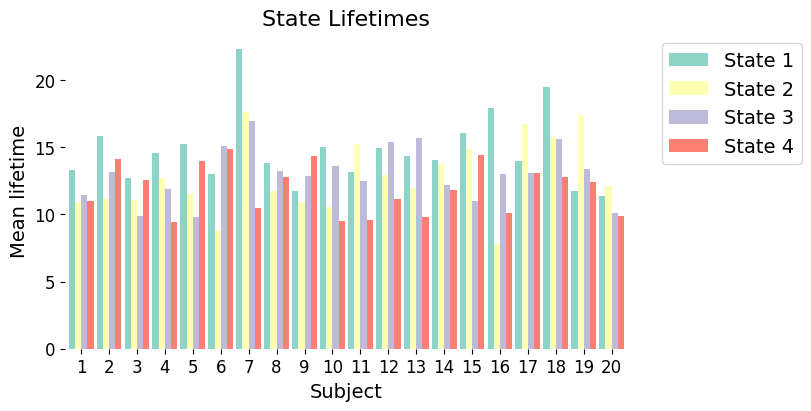

In [22]:
LTmean, LTmed, LTmax = utils.get_life_times(vpath, T_t)
graphics.plot_state_lifetimes(LTmean, num_x_ticks=LTmean.shape[0], ylabel='Mean lifetime')